In [1]:

!pip -q install datasets huggingface_hub scikit-learn seaborn tqdm

import os
import json
import time
import zipfile
import hashlib
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from huggingface_hub import hf_hub_download

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


Using device: cuda


In [2]:

zip_path = hf_hub_download(
    repo_id="uqtwei2/PlantWild",
    filename="plantwild.zip",
    repo_type="dataset"
)

extract_path = "/content/PlantWild"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

base_path = "/content/PlantWild/plantwild"
image_dir = os.path.join(base_path, "images")

print("PlantWild extracted successfully!")


plantwild.zip: reconstructing file:   0%|          |  0.00B / 2.71GB            

plantwild.zip: downloading bytes:           |  0.00B            

PlantWild extracted successfully!


In [3]:

# Load class names
class_names = {}

with open(os.path.join(base_path, "classes.txt")) as f:
    for line in f:
        class_id, class_name = line.strip().split(" ", 1)
        class_names[int(class_id)] = class_name

# Read annotations
records = []

with open(os.path.join(base_path, "trainval.txt")) as f:
    for line in f:
        image_path, class_id, flag = line.strip().rsplit("=", 2)

        records.append({
            "image_path": os.path.join(image_dir, image_path),
            "class_id": int(class_id),
            "class_name": class_names[int(class_id)],
            "flag": int(flag)
        })

df = pd.DataFrame(records)

# Official PlantWild splits
train_df = df[df["flag"] == 1].reset_index(drop=True)
val_df = df[df["flag"] == 2].reset_index(drop=True)
test_df = df[df["flag"] == 0].reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Classes:", len(class_names))


Training: 13045
Validation: 1820
Testing: 3677
Classes: 89


In [4]:

import hashlib
import pandas as pd
from tqdm.auto import tqdm

# Create a fresh copy
df_clean = df.copy()

# Calculate exact image hashes
def file_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()

df_clean["hash"] = [
    file_hash(path)
    for path in tqdm(df_clean["image_path"])
]

# Check whether identical images have conflicting labels
conflicts = df_clean.groupby("hash")["class_id"].nunique()
conflicting_hashes = conflicts[conflicts > 1].index

print("Hashes with conflicting labels:",
      len(conflicting_hashes))

# Remove conflicting-label images from all splits
df_clean = df_clean[
    ~df_clean["hash"].isin(conflicting_hashes)
].copy()

# Priority: test (0), validation (2), training (1)
priority = {0: 0, 2: 1, 1: 2}

df_clean["priority"] = df_clean["flag"].map(priority)

df_clean = df_clean.sort_values("priority")

# Keep only one occurrence of each exact image
df_clean = df_clean.drop_duplicates(
    subset="hash",
    keep="first"
)

# Restore original ordering
df_clean = df_clean.sort_index()

# Rebuild official splits
train_df = df_clean[
    df_clean["flag"] == 1
].reset_index(drop=True)

val_df = df_clean[
    df_clean["flag"] == 2
].reset_index(drop=True)

test_df = df_clean[
    df_clean["flag"] == 0
].reset_index(drop=True)

print("\nAfter duplicate removal:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(df_clean))

# Verify no exact duplicates remain across splits
assert not df_clean["hash"].duplicated().any()

print("\nDuplicate removal successful!")



  0%|          | 0/18542 [00:00<?, ?it/s]

Hashes with conflicting labels: 279

After duplicate removal:
Training: 12573
Validation: 1757
Testing: 3566
Total: 17896

Duplicate removal successful!


In [5]:

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class PlantWildDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        label = int(row["class_id"])
        return self.transform(image), label

train_loader = DataLoader(
    PlantWildDataset(train_df, train_transform),
    batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    PlantWildDataset(val_df, eval_transform),
    batch_size=32, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    PlantWildDataset(test_df, eval_transform),
    batch_size=32, shuffle=False, num_workers=2
)

images, labels = next(iter(train_loader))
print("Image shape:", images.shape)
print("Label shape:", labels.shape)


Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])


In [6]:

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ResNet18
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Replace final classification layer
num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 89)

# Move model to GPU
model = model.to(device)

print("ResNet18 initialized!")
print("Device:", device)
print("Output classes:", model.fc.out_features)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 197MB/s]


ResNet18 initialized!
Device: cuda
Output classes: 89


In [7]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

epochs = 20

print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate: 0.0001")
print("Epochs:", epochs)


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Epochs: 20


In [8]:

import torch
import time
from tqdm.auto import tqdm

# Training history
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")
start_time = time.time()

# Train for 20 epochs
for epoch in range(epochs):

    # =========================
    # TRAINING
    # =========================
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{epochs}"
    ):

        images = images.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track training metrics
        train_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # =========================
    # SAVE METRICS
    # =========================
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "resnet18_best.pth"
        )

        print("Best ResNet18 model saved!")

# Total training time
training_time = time.time() - start_time

print("\nTraining completed!")
print(f"Total time: {training_time/60:.2f} minutes")
print(f"Best validation loss: {best_val_loss:.4f}")


Epoch 1/20:   0%|          | 0/393 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 2. 
  warnings.warn(str(msg))


Epoch 1/20 | Train Loss: 2.8361 | Train Acc: 0.3411 | Val Loss: 1.9486 | Val Acc: 0.4980
Best ResNet18 model saved!


Epoch 2/20:   0%|          | 0/393 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 2. 
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bed1a93b740>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7bed1a93b740>
    self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in

Epoch 2/20 | Train Loss: 1.7406 | Train Acc: 0.5508 | Val Loss: 1.6193 | Val Acc: 0.5686
Best ResNet18 model saved!


... (51 outputs left out)

Epoch 19/20 | Train Loss: 0.1128 | Train Acc: 0.9722 | Val Loss: 1.7140 | Val Acc: 0.6153


Epoch 20/20:   0%|          | 0/393 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 2. 
  warnings.warn(str(msg))
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bed1a93b740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bed1a93b740>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._

Epoch 20/20 | Train Loss: 0.1222 | Train Acc: 0.9695 | Val Loss: 1.7592 | Val Acc: 0.6101

Training completed!
Total time: 53.37 minutes
Best validation loss: 1.3499


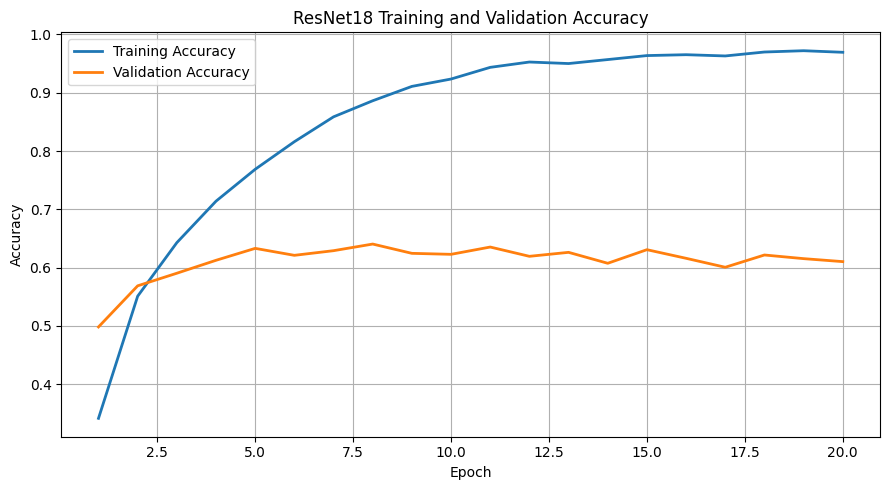

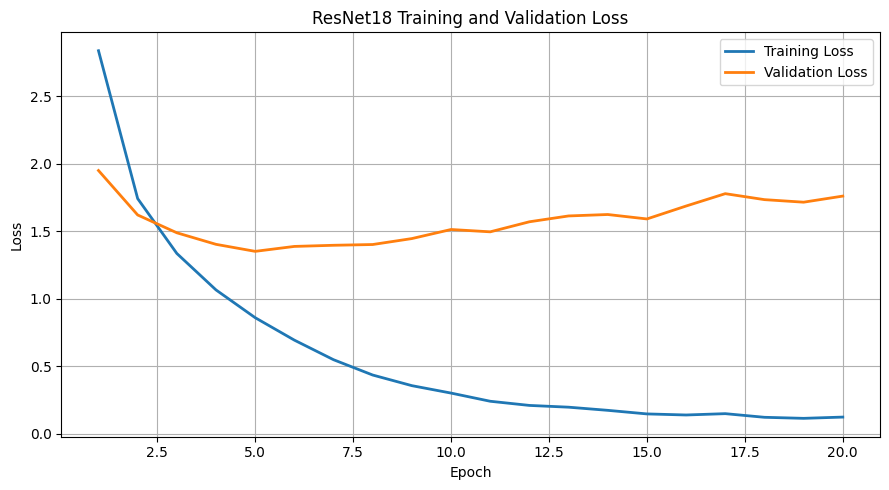

ResNet18 graphs saved!


In [9]:

import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_acc"]) + 1)

# =========================
# ACCURACY GRAPH
# =========================
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    epochs_range,
    history["val_acc"],
    label="Validation Accuracy",
    linewidth=2
)

plt.title("ResNet18 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "resnet18_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# LOSS GRAPH
# =========================
plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.title("ResNet18 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "resnet18_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ResNet18 graphs saved!")


Evaluating ResNet18:   0%|          | 0/112 [00:00<?, ?it/s]


ResNet18 Test Results
Accuracy:  0.6203
Precision: 0.6099
Recall:    0.5672
F1-score:  0.5726

Classification Report:
                                  precision    recall  f1-score   support

                 apple black rot       0.41      0.21      0.27        34
                      apple leaf       0.54      0.66      0.59        87
              apple mosaic virus       0.50      0.24      0.32        34
                      apple rust       0.70      0.69      0.70        58
                      apple scab       0.60      0.47      0.53        57
                     banana leaf       0.78      0.90      0.83        48
           banana panama disease       0.89      0.79      0.84        43
              basil downy mildew       0.45      0.29      0.36        17
                      basil leaf       0.74      0.92      0.82       115
                bean halo blight       0.27      0.16      0.20        19
                       bean leaf       0.33      0.45      0.38   

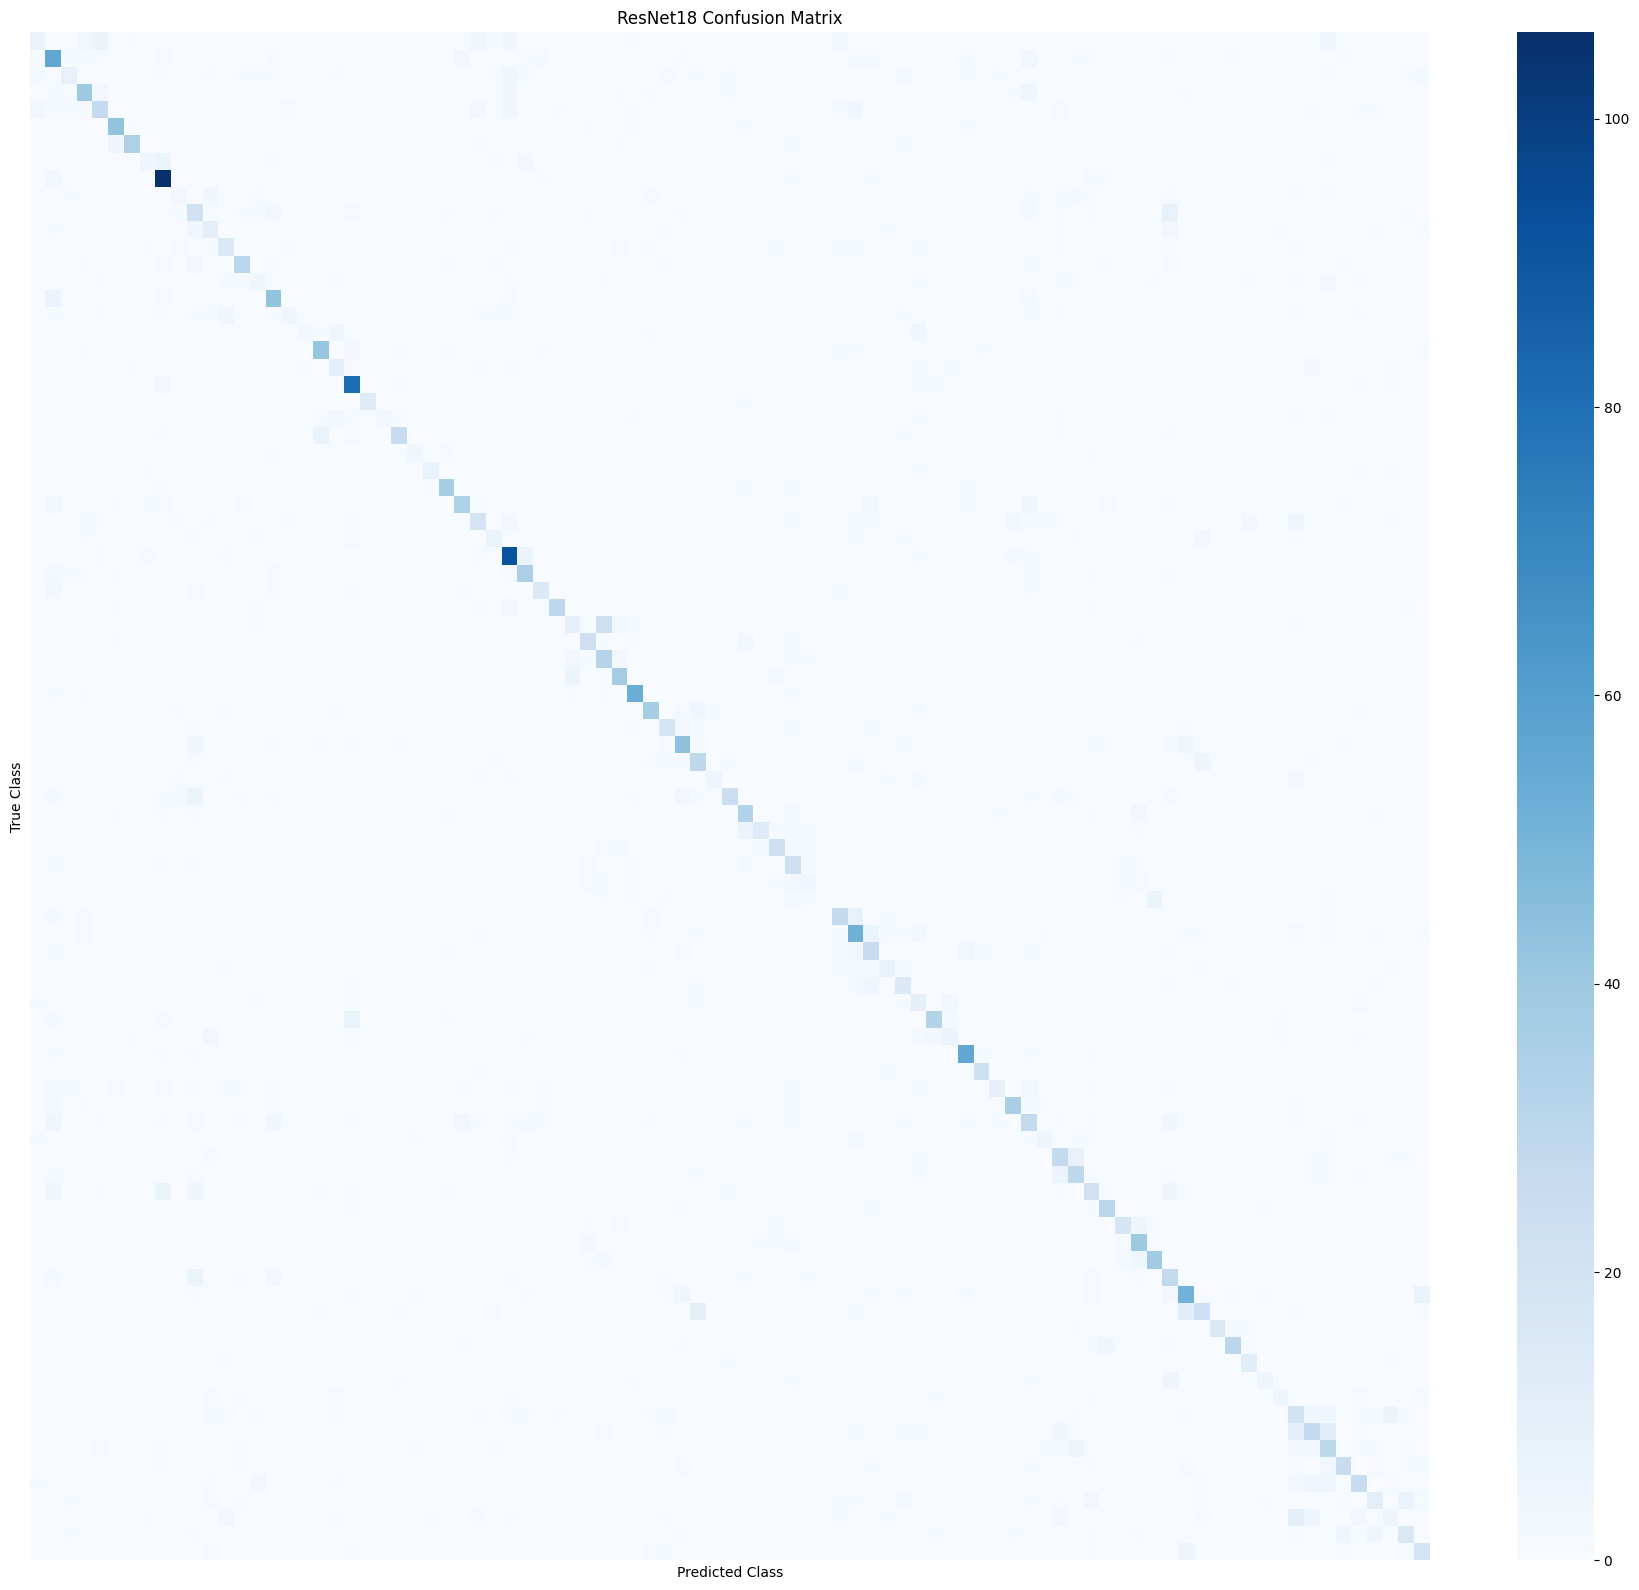


ResNet18 evaluation completed!
All results saved successfully!


In [10]:

import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# =========================
# LOAD BEST MODEL
# =========================
model.load_state_dict(
    torch.load(
        "resnet18_best.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

y_true = []
y_pred = []

# =========================
# TEST EVALUATION
# =========================
with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Evaluating ResNet18"
    ):

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(
            labels.cpu().numpy().tolist()
        )

        y_pred.extend(
            predictions.cpu().numpy().tolist()
        )

# =========================
# CALCULATE METRICS
# =========================
accuracy = accuracy_score(y_true, y_pred)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(89)),
    average="macro",
    zero_division=0
)

print("\nResNet18 Test Results")
print("==========================")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# =========================
# CLASSIFICATION REPORT
# =========================
ordered_classes = [
    class_names[i] for i in range(89)
]

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(89)),
    target_names=ordered_classes,
    zero_division=0
)

print("\nClassification Report:")
print(report)

with open("resnet18_classification_report.txt", "w") as f:
    f.write(report)

# =========================
# CONFUSION MATRIX
# =========================
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(89))
)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=False,
    yticklabels=False
)

plt.title("ResNet18 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.savefig(
    "resnet18_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# =========================
# SAVE CLASS NAMES
# =========================
with open("class_names.json", "w") as f:
    json.dump(ordered_classes, f, indent=2)

# =========================
# SAVE PERFORMANCE METRICS
# =========================
metrics = {
    "model": "ResNet18",
    "accuracy": float(accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1": float(f1),
    "training_seconds": float(training_time),
    "epochs": len(history["train_acc"]),
    "best_validation_loss": float(best_val_loss),
    "test_samples": len(y_true)
}

with open("resnet18_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# Save training history
with open("resnet18_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("\nResNet18 evaluation completed!")
print("All results saved successfully!")
